In [34]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path
import sys

# 1. Get the absolute path to the root directory (MARKETLAB)
parent_dir = Path.cwd().parent

# 2. Add root to sys.path so Python can find the 'src' folder
if str(parent_dir) not in sys.path:
    sys.path.append(str(parent_dir))

# 3. Import from the src module
from src.backtesting import generate_ewma_strategy, analyze_drawdown_metrics

plt.style.use('seaborn-v0_8-darkgrid')

# 4. Define paths relative to the root
PROCESSED_DIR = parent_dir / "data" / "processed"

# 5. Load data
spy = pd.read_csv(PROCESSED_DIR / "SPY_processed.csv", index_col='Date', parse_dates=True)

# 6. Generate Strategy
spy = generate_ewma_strategy(spy)

# 7. Filter to Out-of-Sample Test Period
test_spy = spy.loc['2022-01-01':]

buy_hold_cum = (1 + test_spy['Daily_Return']).cumprod()
strategy_cum = (1 + test_spy['Net_Strategy_Return']).cumprod()

In [35]:
print("=== OUT-OF-SAMPLE DRAWDOWN PROFILE (2022-2024) ===\n")

bh_metrics = analyze_drawdown_metrics(buy_hold_cum, "Buy & Hold")
strat_metrics = analyze_drawdown_metrics(strategy_cum, "EWMA Strategy")

=== OUT-OF-SAMPLE DRAWDOWN PROFILE (2022-2024) ===

=== BUY & HOLD DRAWDOWN PROFILE ===
Deepest Drawdown: -24.50%
  Time to Trough:    282 calendar days
  Recovery Duration: 427.0 calendar days
  Total Underwater:  709.0 calendar days
Longest Underwater Period: 709.0 days


=== EWMA STRATEGY DRAWDOWN PROFILE ===
Deepest Drawdown: -11.10%
  Time to Trough:    67 calendar days
  Recovery Duration: 63.0 calendar days
  Total Underwater:  130.0 calendar days
Longest Underwater Period: 170.0 days




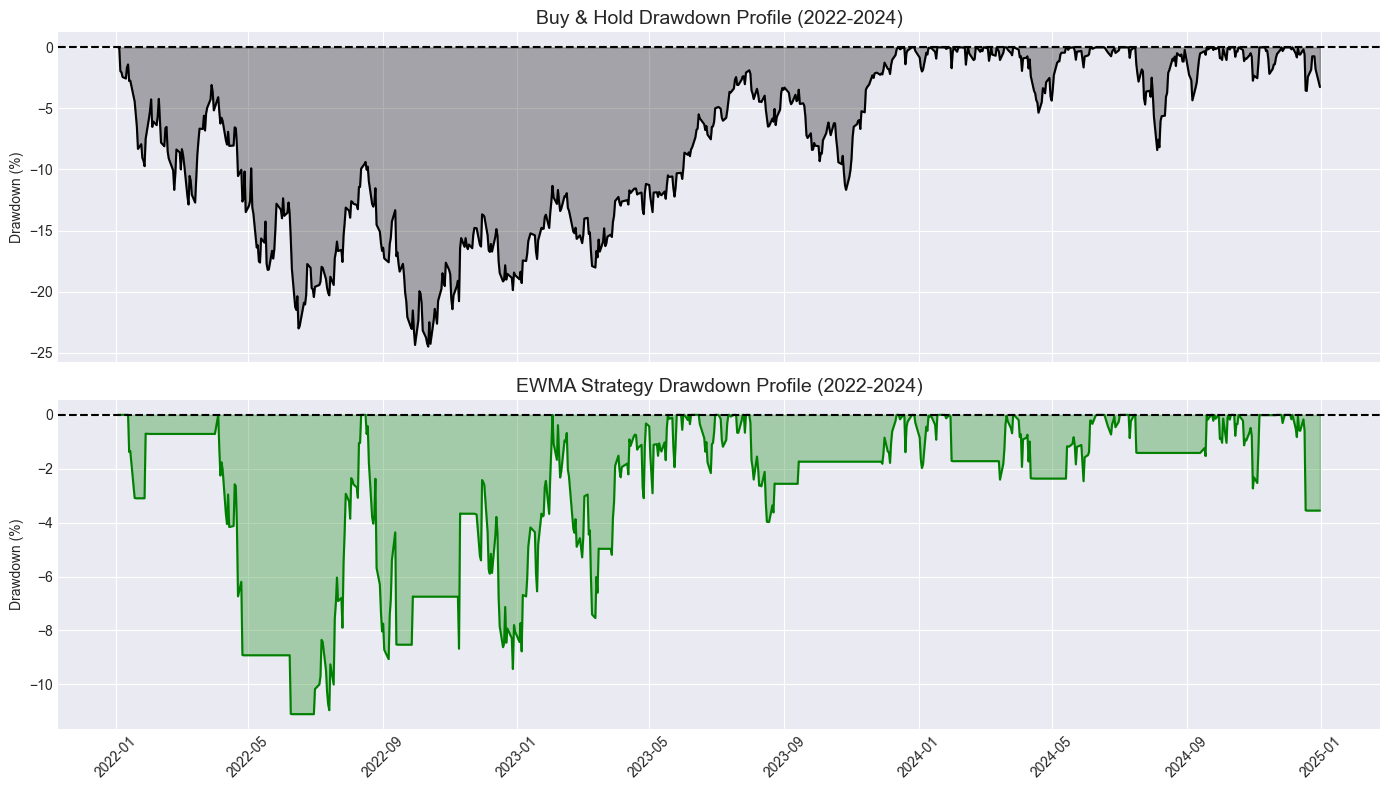

In [36]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

# Calculate drawdowns for plotting
dd_bh = (buy_hold_cum / buy_hold_cum.cummax()) - 1
dd_strat = (strategy_cum / strategy_cum.cummax()) - 1

# Plot Buy & Hold Drawdown
ax1.plot(dd_bh.index, dd_bh * 100, color='black', linewidth=1.5)
ax1.fill_between(dd_bh.index, dd_bh * 100, 0, color='black', alpha=0.3)
ax1.set_title("Buy & Hold Drawdown Profile (2022-2024)", fontsize=14)
ax1.set_ylabel("Drawdown (%)")
ax1.axhline(0, color='black', linestyle='--')

# Plot Strategy Drawdown
ax2.plot(dd_strat.index, dd_strat * 100, color='green', linewidth=1.5)
ax2.fill_between(dd_strat.index, dd_strat * 100, 0, color='green', alpha=0.3)
ax2.set_title("EWMA Strategy Drawdown Profile (2022-2024)", fontsize=14)
ax2.set_ylabel("Drawdown (%)")
ax2.axhline(0, color='black', linestyle='--')

plt.gca().xaxis.set_major_formatter(mdates.DateFormatter('%Y-%m'))
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [37]:
# ==========================================
# FINAL VERIFICATION: DRAWDOWN RECOVERY LOGIC
# ==========================================
import pandas as pd
import numpy as np
import sys
from pathlib import Path
import importlib

# 1. Force reload the module to ensure the latest code is used
parent_dir = Path.cwd().parent
if str(parent_dir) not in sys.path:
    sys.path.append(str(parent_dir))

import src.backtesting
importlib.reload(src.backtesting)
from src.backtesting import analyze_drawdown_metrics

print("=== VERIFYING DRAWDOWN RECOVERY LOGIC ===\n")

# 2. Re-calculate the metrics
bh_metrics = analyze_drawdown_metrics(buy_hold_cum, "Buy & Hold")
strat_metrics = analyze_drawdown_metrics(strategy_cum, "EWMA Strategy")

# 3. Verification Function
def verify_episode(metrics_df, label, cumulative_series):
    if metrics_df.empty:
        print(f"{label}: No data.")
        return
        
    # Find the index of the deepest drawdown manually
    deepest_idx = metrics_df['max_depth'].idxmin()
    deepest = metrics_df.loc[deepest_idx]
    
    print(f"--- {label} Deepest Drawdown ---")
    
    # Use dictionary-style access which is less prone to pandas index confusion
    print(f"Peak Date:     {deepest['peak_date'].date()}")
    print(f"Trough Date:   {deepest['trough_date'].date()}")
    print(f"Max Depth:     {deepest['max_depth']*100:.2f}%")
    
    # Assertion 1: Peak must strictly precede Trough
    assert deepest['peak_date'] < deepest['trough_date'], "Error: Peak must be before Trough!"
    
    if deepest['is_recovered']:
        recovery_date = deepest['trough_date'] + pd.Timedelta(days=deepest['recovery_duration'])
        print(f"Recovery Date: {recovery_date.date()}")
        
        # Assertion 2: Recovery must strictly follow Trough
        assert recovery_date > deepest['trough_date'], "Error: Recovery must be after Trough!"
        print("Status: RECOVERED (Verification Passed)\n")
    else:
        print("Status: UNRECOVERED / RIGHT-CENSORED (Verification Passed)\n")
        
    # Assertion 3: Ensure the peak was actually a high-water mark
    peak_val = cumulative_series.loc[deepest['peak_date']]
    print(f"Peak Value:    {peak_val:.4f}")
    print(f"Trough Value:  {peak_val * (1 + deepest['max_depth']):.4f}\n")

# 4. Run the verification
verify_episode(bh_metrics, "Buy & Hold", buy_hold_cum)
verify_episode(strat_metrics, "EWMA Strategy", strategy_cum)

=== VERIFYING DRAWDOWN RECOVERY LOGIC ===

=== BUY & HOLD DRAWDOWN PROFILE ===
Deepest Drawdown: -24.50%
  Time to Trough:    282 calendar days
  Recovery Duration: 427.0 calendar days
  Total Underwater:  709.0 calendar days
Longest Underwater Period: 709.0 days


=== EWMA STRATEGY DRAWDOWN PROFILE ===
Deepest Drawdown: -11.10%
  Time to Trough:    67 calendar days
  Recovery Duration: 63.0 calendar days
  Total Underwater:  130.0 calendar days
Longest Underwater Period: 170.0 days


--- Buy & Hold Deepest Drawdown ---
Peak Date:     2022-01-03
Trough Date:   2022-10-12
Max Depth:     -24.50%
Recovery Date: 2023-12-13
Status: RECOVERED (Verification Passed)

Peak Value:    1.0058
Trough Value:  0.7594

--- EWMA Strategy Deepest Drawdown ---
Peak Date:     2022-04-04
Trough Date:   2022-06-10
Max Depth:     -11.10%
Recovery Date: 2022-08-12
Status: RECOVERED (Verification Passed)

Peak Value:    1.0131
Trough Value:  0.9006



In [38]:
# ==========================================
# INDEPENDENT VERIFICATION: DRAWDOWN RECOVERY
# ==========================================
import pandas as pd
import numpy as np

def verify_recovery(cumulative_series, metrics, label):
    """
    Independently verifies that recovery dates are correct by searching the actual equity curve.
    """
    print(f"--- Verifying {label} ---")
    passed = 0
    
    for idx, episode in metrics.iterrows():
        if not episode['is_recovered']:
            continue
            
        peak_value = cumulative_series.loc[episode['peak_date']]
        
        # Search the equity curve starting from the trough
        recovery_candidates = cumulative_series.loc[episode['trough_date']:]
        recovery_candidates = recovery_candidates[recovery_candidates >= peak_value]
        
        assert not recovery_candidates.empty, f"Error: Recovery date not found for episode {idx}."
        
        actual_recovery_date = recovery_candidates.index[0]
        actual_duration = (actual_recovery_date - episode['trough_date']).days
        
        assert actual_duration == episode['recovery_duration'], (
            f"Error: Duration mismatch for episode {idx}. "
            f"Expected {episode['recovery_duration']}, found {actual_duration}."
        )
        passed += 1
        
    print(f"Verified {passed} recovered episodes. Status: PASSED.\n")

# Run the independent verification
verify_recovery(buy_hold_cum, bh_metrics, "Buy & Hold")
verify_recovery(strategy_cum, strat_metrics, "EWMA Strategy")

--- Verifying Buy & Hold ---
Verified 31 recovered episodes. Status: PASSED.

--- Verifying EWMA Strategy ---
Verified 33 recovered episodes. Status: PASSED.



## Experiment F Conclusion: Drawdown Profile Analysis

### 1. Importance of Drawdown Metrics
Maximum drawdown alone does not fully describe capital impairment. This analysis distinguishes between:
- **Depth:** Maximum percentage decline from a previous high-water mark.
- **Time to Trough:** Calendar days between the peak and the lowest point.
- **Recovery Duration:** Calendar days between the trough and recovery.
- **Total Underwater Duration:** Calendar days between the previous peak and recovery.

### 2. Quantitative Findings
The metrics below are generated using `src.backtesting.analyze_drawdown_metrics`.

- **Buy & Hold:** 
  - Deepest Drawdown: **-24.50%**
  - Time to Trough: 282 days
  - Recovery Duration: 427 days
  - Total Underwater (Peak to Recovery): **709 calendar days**
- **EWMA Strategy:** 
  - Deepest Drawdown: **-11.10%**
  - Time to Trough: 67 days
  - Recovery Duration: 63 days
  - Total Underwater (Peak to Recovery): **130 calendar days**
  - Longest Completed Underwater Period: **170 calendar days**

### 3. Interpretation
The analysis compares the depth and duration of drawdowns experienced by the Buy & Hold benchmark and the EWMA volatility-filtered strategy. The results provide evidence about historical drawdown behaviour during the selected evaluation period. They should not be interpreted as proof that the strategy will reduce drawdowns in future market conditions.

### Conclusion
The EWMA strategy demonstrated lower historical drawdown severity than the Buy & Hold benchmark during the selected test period. Further testing across additional assets, market regimes and execution assumptions is required before establishing the robustness of this result.